# XAI traffic forecasting: 32-new-target replication

A complete analysis companion to the original training notebook. **This study reuses locked forecasters; it does not retrain them.** The original study used 32 sources, eight validation institutions and eight targets. This replication adds 32 previously unevaluated targets matched to the same 32 source anchors. Across both studies there are 80 unique institutions, within one ISP.

Read `PROTOCOL_REPLICATION.md`. Membership, timestamps, models and scientific code were locally hashed before new-target scoring. The original outcome was already known. This is not external preregistration, an independent ISP replication, or evidence of causal demand effects.

Run from this folder or its parent. Data and checkpoints are included. Ordinary execution reads completed batch results and reproduces local arithmetic, plots and an independent primary point estimate. The final cell provides optional full evaluation on a **copy**. Original model fitting remains documented in `../xai_cross_institution/XAI_Complete_Experiment.ipynb`.

In [1]:
from pathlib import Path
import sys, os, json, hashlib, platform, time
os.environ.setdefault('OPENBLAS_NUM_THREADS','4')
ROOT=Path.cwd()
if not (ROOT/'PROTOCOL_REPLICATION.md').exists():
    candidates=[ROOT/'xai_replication_32',ROOT/'outputs/xai_replication_32']
    ROOT=next(p for p in candidates if (p/'PROTOCOL_REPLICATION.md').exists())
sys.path.insert(0,str(ROOT/'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from IPython.display import display, Markdown
from math import factorial
from torch import nn
from numpy.polynomial.legendre import leggauss
from data_common import windows
from benchmark_common import Predictor, MASKS, REMOVED, PERMUTATIONS, SHAPLEY_WEIGHTS, NODES, order
from neural_feasibility import Forecaster
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
torch.set_num_threads(4)
def readjson(name):return json.loads((ROOT/'results'/name).read_text())
print(platform.platform(), platform.python_version(), 'Torch',torch.__version__)
print('Project:',ROOT)

macOS-26.5.2-arm64-arm-64bit 3.11.15 Torch 2.15.0
Project: /Users/farrelardya/Documents/Codex/2026-11-05/ca/outputs/xai_replication_32


## 1. Provenance and frozen design
The freeze records the unscored historical state. Completion is recorded separately; do not rewrite frozen manifests after execution.

In [2]:
freeze=readjson('PREEVALUATION_FREEZE.json')
display(freeze if 'files' not in freeze else {k:v for k,v in freeze.items() if k!='files'})
assert all(hashlib.sha256((ROOT/p).read_bytes()).hexdigest()==h for p,h in freeze['files'].items())
print('Verified frozen file hashes:',len(freeze['files']))
display(readjson('PREPARATION.json'))

{'frozen_utc': '2026-11-06T18:44:34.047509+00:00',
 'new_target_outcomes_scored': False,
 'original_target_outcomes_already_known': True,
 'external_preregistration': False,
 'models_retrained': False,
 'source_anchors_reused': True}

Verified frozen file hashes: 100


{'status': 'prepared',
 'runtime_seconds': 4.756486541999038,
 'source_series': 32,
 'new_target_series': 32,
 'main_histories': 2016,
 'dense_histories': 8064,
 'new_target_performance_scored': False}

In [3]:
split=pd.read_csv(ROOT/'INSTITUTION_SPLIT.csv')
pairs=pd.read_csv(ROOT/'MATCHED_PAIRS.csv')
display(split.head()); display(pairs.head())
assert split.id.nunique()==64
print(split.groupby('role').size() if 'role' in split else split.groupby('cohort').size())

,id,role,volume_stratum,median_gb,std_gb,coverage,sha256,assignment_hash
0,72,source,0,0.001081,0.103406,1.000000,6e4c1208bc1e8d1a6c50adb61e4960e941f0a050503709...,locked_original_source
1,99,source,0,0.004043,0.332105,0.999049,d641a4a33b14f6d7114bdbda540df6f0bc42637107904a...,locked_original_source
2,274,source,0,0.000188,0.073445,0.999881,f41438baa031aede8d8eaa50a5d90c8d7d42cfb063f9ec...,locked_original_source
3,281,source,0,0.000004,0.000003,1.000000,97a5d6a4d5b8790f1d023ea553cb587163827cead148d5...,locked_original_source
4,260,source,0,0.000522,0.133614,0.990611,4093cde702444bc0916d697dab31e5b6f9d32116947a92...,locked_original_source


,pair,volume_stratum,source,target,training_descriptor_distance
0,0,0,4,221,0.112417
1,1,0,260,8,0.372692
2,2,0,265,252,0.385608
3,3,0,255,214,0.695516
4,4,0,281,267,0.080257


role
source    32
target    32
dtype: int64


## 2. Membership and matching
Targets were hash-ranked within four original 2024 volume strata. Matching uses 2024 descriptors, not final forecast/XAI outcomes. The old targets and 12 development institutions were excluded. Source anchors are reused, so old and new estimates are not pooled as independent replications.

In [4]:
display(pd.read_csv(ROOT/'UNUSED_ELIGIBLE_POOL_2024.csv').head())
print('Matching columns:',pairs.columns.tolist())
display(pairs.describe(include='all'))

,id,coverage,median_gb,std_gb,eligible,sha256,stratum,selected,volume_stratum,assignment_hash
0,267,0.995484,9.520000e-07,8.113978e-07,True,043693c701e96759cdbc01be3d612bcb59177011df9eb8...,0,False,0,116ca4873b1066eee39fb4dceb96cb2d6664c02afca955...
1,243,0.996553,1.177000e-06,1.190791e-01,True,b9cdf7c56df96167e69f1553268fbef4e0f90e50eb677d...,0,False,0,d454e80aaa4d27c54700f7197cebbf31c6ec4974cc82d2...
2,279,0.999643,1.361000e-06,1.240437e-06,True,584fe490f1d3773cc6c5dada924280ce3ed5cbe47a82cb...,0,False,0,7c261c70abe2df26d4bc77939e8943f727967d3c81cd9c...
3,280,0.999287,1.511000e-06,2.132879e-05,True,52013fbd02ff49e40bf5bfd325d99eccd69295b0337142...,0,False,0,e8d1dd585ba8e7bd225532cb7cbf1f8c300c2d550e2410...
4,266,0.999049,2.858500e-06,2.139554e-06,True,20f5e85fb12cf6c3ec65482c1c92d00cdf119021207df4...,0,False,0,45657062a4389ca104d436bdfdf460e3bee26a97e289fa...


Matching columns: ['pair', 'volume_stratum', 'source', 'target', 'training_descriptor_distance']


,pair,volume_stratum,source,target,training_descriptor_distance
count,32.000000,32.000000,32.000000,32.000000,32.000000
mean,15.500000,1.500000,120.031250,140.562500,0.696725
std,9.380832,1.135924,91.213852,75.453869,0.521605
min,0.000000,0.000000,0.000000,8.000000,0.080257
25%,7.750000,0.750000,45.250000,79.000000,0.325049
50%,15.500000,1.500000,95.500000,149.000000,0.555086
75%,23.250000,2.250000,206.250000,206.500000,1.090625
max,31.000000,3.000000,281.000000,267.000000,1.964264


In [5]:
main_plan=pd.read_csv(ROOT/'results/SELECTION_MAIN_FROZEN.csv')
dense_plan=pd.read_csv(ROOT/'results/SELECTION_DENSE_FROZEN.csv')
availability=pd.read_csv(ROOT/'results/AVAILABILITY.csv')
assert set(zip(main_plan.id,main_plan.origin)) <= set(zip(dense_plan.id,dense_plan.origin))
print('Histories:',len(main_plan),'main;',len(dense_plan),'dense')
display(availability)
display(main_plan.groupby(['cohort','year']).size().rename('histories'))

Histories: 2016 main; 8064 dense


,pair,year,source,target,source_eligible,target_eligible,common_eligible,main_origins,dense_origins
0,0,2025,4,221,307,307,307,16,64
1,0,2026,4,221,129,129,129,16,64
2,1,2025,260,8,307,307,307,16,64
3,1,2026,260,8,114,0,0,0,0
4,2,2025,265,252,307,307,307,16,64
...,...,...,...,...,...,...,...,...,...
59,29,2026,95,116,129,129,129,16,64
60,30,2025,53,80,307,307,307,16,64
61,30,2026,53,80,129,129,129,16,64
62,31,2025,225,130,307,307,307,16,64


cohort  year
source  2025    512
        2026    496
target  2025    512
        2026    496
Name: histories, dtype: int64

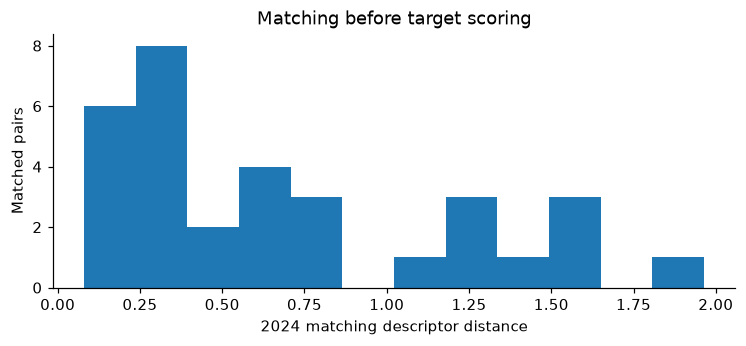

In [6]:
fig,ax=plt.subplots(figsize=(8,3));ax.hist(pairs.training_descriptor_distance,bins=12);ax.set(xlabel='2024 matching descriptor distance',ylabel='Matched pairs',title='Matching before target scoring');plt.show()

## 3. Inspect hourly data and eligible windows
Observed zero traffic remains zero; missing values remain missing. Every input contains 168 usable hourly values. Both endpoint labels must be observed. The native coverage and artifact flags are part of the saved data, not inferred from XAI outputs.

In [7]:
case=main_plan.sort_values(['pair','year','cohort','origin']).iloc[0]
id0=int(case.id)
hourly=pd.read_csv(ROOT/f'data/institution_{id0}.csv.gz')
display(hourly.head());display(hourly.describe(include='all'))

,id_time,time,coverage_10min,complete_hour,conservative_artifact_flag,n_bytes
0,0,2023-10-09 00:00:00+00:00,6,True,False,6403764.0
1,1,2023-10-09 01:00:00+00:00,6,True,False,6224402.0
2,2,2023-10-09 02:00:00+00:00,6,True,False,40803227.0
3,3,2023-10-09 03:00:00+00:00,6,True,False,281785748.0
4,4,2023-10-09 04:00:00+00:00,6,True,False,383567775.0


,id_time,time,coverage_10min,complete_hour,conservative_artifact_flag,n_bytes
count,23902.000000,23902,23902.000000,23902,23902,2.345000e+04
unique,NaN,23902,NaN,2,2,NaN
top,NaN,2023-10-09 00:00:00+00:00,NaN,True,False,NaN
freq,NaN,1,NaN,23417,23542,NaN
mean,11950.500000,NaN,5.883859,NaN,NaN,9.754980e+07
std,6900.057403,NaN,0.821442,NaN,NaN,2.298660e+08
min,0.000000,NaN,0.000000,NaN,NaN,8.720000e+03
25%,5975.250000,NaN,6.000000,NaN,NaN,2.848114e+06
50%,11950.500000,NaN,6.000000,NaN,NaN,7.943408e+06
75%,17925.750000,NaN,6.000000,NaN,NaN,4.225925e+07


Window fields: ['X', 'Y', 'o', 't', 'y', 'valid']


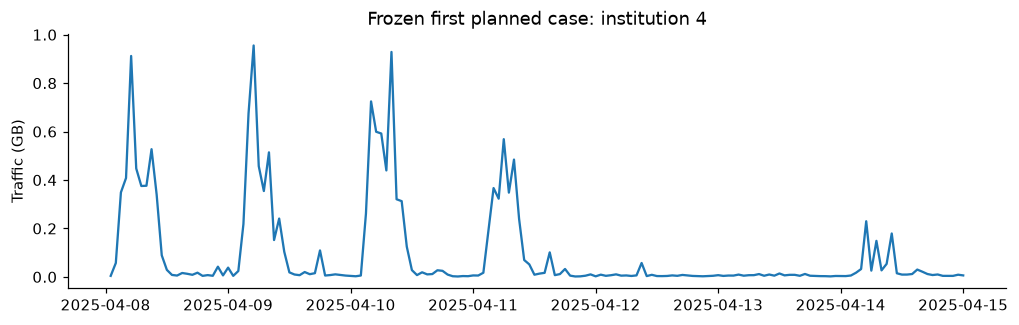

In [8]:
v=windows(ROOT/f'data/institution_{id0}.csv.gz')
print('Window fields:',list(v))
o=int(v['t'].get_loc(pd.Timestamp(case.origin)))
j=int(np.flatnonzero(v['o']==o)[0]);x=v['X'][j]
t=v['t'][o-167:o+1]
assert len(x)==168 and np.isfinite(x).all() and (x>=0).all()
fig,ax=plt.subplots(figsize=(11,3));ax.plot(t,x);ax.set(ylabel='Traffic (GB)',title=f'Frozen first planned case: institution {id0}');plt.show()

## 4. Locked forecasters and deployment semantics
The output includes log transformation, source normalization and nonnegative clipping. Attribution must explain this deployed function. Checkpoints are the original source-trained bytes. No target fitting occurs here.

In [9]:
display(readjson('LOCKED_MODEL_REFERENCE.json'))
models={kind:Predictor(kind,0 if kind=='ridge' else 42) for kind in ['ridge','dlinear','gru']}
display(pd.DataFrame({k:m(x) for k,m in models.items()},index=['h=1','h=6']).T)
for kind,m in models.items():
    print(kind,'torch parameters:',sum(p.numel() for p in m.net.parameters()),'buffer values:',sum(p.numel() for p in m.net.buffers()))

{'status': 'training_complete',
 'runtime_seconds': 318.21448397636414,
 'source_institutions': 32,
 'validation_institutions': 8,
 'target_institutions_fitted': 0,
 'source_windows': 227478,
 'normalization_mean': 0.4941546320915222,
 'normalization_std': 0.9291831851005554,
 'models': [{'file': 'dlinear_123.pt',
   'sha256': '926e52c1f80172275623d28ee1f88294f2afd3b033a66d0805a71d037494cf98'},
  {'file': 'dlinear_2026.pt',
   'sha256': 'fd1c3f33b15a79257b504508669107f5ef85b9fa749f74c5366fb4cb610092b7'},
  {'file': 'dlinear_42.pt',
   'sha256': 'eadaeb43e78cd403866961bb48869406da6926ee9fac46d23e0453cb8b1adb6e'},
  {'file': 'gru_123.pt',
   'sha256': 'df147f43a884ba259cba6761d65717bdd9e4896a8543a7032881271819f350a1'},
  {'file': 'gru_2026.pt',
   'sha256': 'e98a6e62c09a80797a2c5a6145ff36694247c12aaa8d000082c0fc07ec167cf1'},
  {'file': 'gru_42.pt',
   'sha256': '93dfb04731f00be7e098a8471fcee3c02fdcaf2266fa38175a0ffe9a41443d74'},
  {'file': 'ridge_0.npz',
   'sha256': '1d34ad31da9df36c056

,h=1,h=6
ridge,0.016681,0.328504
dlinear,0.024136,0.327947
gru,0.076389,0.128084


ridge torch parameters: 0 buffer values: 338
dlinear torch parameters: 676 buffer values: 2
gru torch parameters: 3426 buffer values: 2


The following executable definitions expose the actual inference wrapper; the imported checkpoints remain fixed.

In [10]:
class RidgeModule(nn.Module):
 def __init__(self,coef,intercept):
  super().__init__();self.register_buffer('coef',torch.tensor(coef,dtype=torch.float64));self.register_buffer('intercept',torch.tensor(intercept,dtype=torch.float64))
 def log_prediction(self,x):return x@self.coef.T+self.intercept
 def forward(self,x):return torch.expm1(torch.clamp_min(self.log_prediction(torch.log1p(x)),0))

class Predictor:
 def __init__(self,kind,seed):
  self.kind=kind;self.seed=seed
  if kind=='ridge':
   m=np.load(ROOT/'models/ridge_0.npz');self.net=RidgeModule(m['coef'],m['intercept'])
  else:
   d=torch.load(ROOT/f'models/{kind}_{seed}.pt',weights_only=True,map_location='cpu');self.net=Forecaster(kind,d['mean'],d['std']);self.net.load_state_dict(d['state']);self.net.double()
  self.net.eval()
 def __call__(self,x,bias=None,rawlog=False):
  x=np.asarray(x,dtype=float);flat=x.reshape(-1,168);chunks=[]
  with torch.no_grad():
   for a in range(0,len(flat),512):
    t=torch.tensor(flat[a:a+512],dtype=torch.float64);z=self.net.log_prediction(torch.log1p(t));
    if bias is not None:z=z+torch.tensor(bias,dtype=torch.float64)
    y=z if rawlog else torch.expm1(torch.clamp_min(z,0));chunks.append(y.numpy())
  return np.concatenate(chunks).reshape(x.shape[:-1]+(2,))

The neural architecture below is executable and identical to the locked implementation. No optimizer or fitting is run in this replication.

In [11]:
class Forecaster(nn.Module):
 def __init__(self,kind,mean,std):
  super().__init__();self.kind=kind;self.register_buffer('mean',torch.tensor(float(mean)));self.register_buffer('std',torch.tensor(float(std)))
  if kind=='gru':self.gru=nn.GRU(1,32,batch_first=True);self.head=nn.Linear(32,2);nn.init.zeros_(self.head.weight);nn.init.zeros_(self.head.bias)
  else:
   self.trend=nn.Linear(168,2);self.season=nn.Linear(168,2)
   for m in [self.trend,self.season]:nn.init.constant_(m.weight,1/168);nn.init.zeros_(m.bias)
 def log_prediction(self,x):
  z=(x-self.mean)/self.std
  if self.kind=='gru':_,h=self.gru(z.unsqueeze(-1));return x[:,-1,None]+self.head(h[-1])*self.std
  trend=torch.nn.functional.avg_pool1d(torch.nn.functional.pad(z[:,None,:],(12,12),mode='replicate'),25,1)[:,0,:]
  return (self.trend(trend)+self.season(z-trend))*self.std+self.mean
 def forward(self,gb):return torch.expm1(torch.clamp_min(self.log_prediction(torch.log1p(gb)),0))

## 5. Forecast performance: separate from explanation reliability
Macro scores average seeds first. Different years have unequal availability. MASE compares absolute forecast error with the source-defined seasonal scale; values below one beat that scale, not every possible baseline.

,model,role,arm,horizon,mae_gb,rmse_gb,mase,negative_fraction,zero_fraction
0,daily,source,calibrated,1,1.026230,1.672921,1.261291,0.0,0.002196
1,daily,source,calibrated,6,1.104215,1.834071,1.424582,0.0,0.004134
2,daily,source,frozen,1,1.030844,1.685654,1.262645,0.0,0.000000
3,daily,source,frozen,6,1.114362,1.841835,1.426659,0.0,0.000000
4,daily,target,calibrated,1,2.195480,5.986124,1.863792,0.0,0.000861
5,daily,target,calibrated,6,1.892563,4.355611,1.824948,0.0,0.000738
6,daily,target,frozen,1,2.197269,5.990576,1.864201,0.0,0.000000
7,daily,target,frozen,6,1.896324,4.363719,1.824290,0.0,0.000000
8,dlinear,source,calibrated,1,0.747894,1.198776,0.831291,0.0,0.133583
9,dlinear,source,calibrated,6,0.956402,1.544124,1.086461,0.0,0.154811


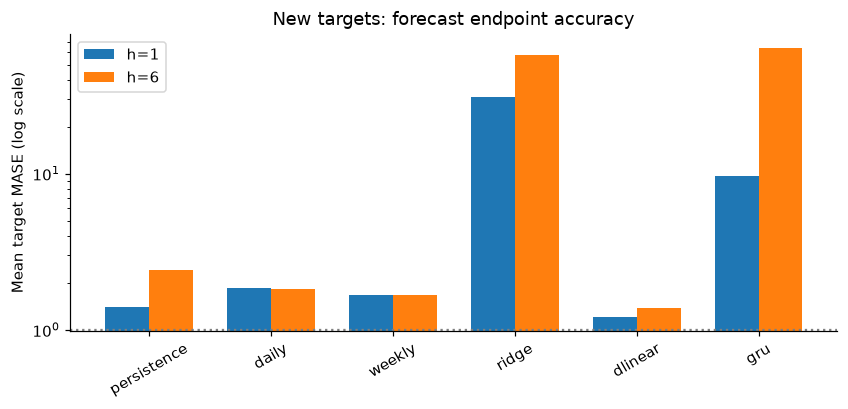

In [12]:
forecast=pd.read_csv(ROOT/'results/forecast_macro.csv')
display(forecast)
plotdata=forecast.query("role=='target' and arm=='frozen'")
fig,ax=plt.subplots(figsize=(9,3.5))
names=['persistence','daily','weekly','ridge','dlinear','gru']; centers=np.arange(len(names))
for offset,(h,g) in zip([-.18,.18],plotdata.groupby('horizon')):ax.bar(centers+offset,g.set_index('model').loc[names].mase,.36,label=f'h={h}')
ax.set_yscale('log');ax.axhline(1,color='gray',ls=':');ax.set(xticks=centers,xticklabels=names,ylabel='Mean target MASE (log scale)',title='New targets: forecast endpoint accuracy');ax.legend();plt.xticks(rotation=30);plt.show()

In [13]:
display(pd.read_csv(ROOT/'results/forecast_equal_institution_macro.csv'))
display(pd.read_csv(ROOT/'results/forecast_per_year_macro.csv'))

,model,role,arm,horizon,mae_gb,rmse_gb,mase
0,daily,source,calibrated,1,1.026230,1.672921,1.261291
1,daily,source,calibrated,6,1.104215,1.834071,1.424582
2,daily,source,frozen,1,1.030844,1.685654,1.262645
3,daily,source,frozen,6,1.114362,1.841835,1.426659
4,daily,target,calibrated,1,2.161643,5.893805,1.848804
5,daily,target,calibrated,6,1.863579,4.289360,1.814175
6,daily,target,frozen,1,2.163404,5.898188,1.849206
7,daily,target,frozen,6,1.867281,4.297342,1.813527
8,dlinear,source,calibrated,1,0.747894,1.198776,0.831291
9,dlinear,source,calibrated,6,0.956402,1.544124,1.086461


,model,role,year,arm,horizon,mae_gb,rmse_gb,mase
0,daily,source,2025,calibrated,1,1.031875,1.623745,1.107645
1,daily,source,2025,calibrated,6,1.140183,1.804694,1.291132
2,daily,source,2025,frozen,1,1.031875,1.623745,1.107645
3,daily,source,2025,frozen,6,1.140183,1.804694,1.291132
4,daily,source,2026,calibrated,1,1.020584,1.722096,1.414937
...,...,...,...,...,...,...,...,...
91,weekly,target,2025,frozen,6,1.363004,2.252154,1.739006
92,weekly,target,2026,calibrated,1,2.814051,9.207847,1.828724
93,weekly,target,2026,calibrated,6,2.275501,6.161957,1.655115
94,weekly,target,2026,frozen,1,2.966542,9.742331,1.797937


### Post-hoc MASE scale diagnostic
After observing extreme macro MASE, this descriptive view retains all cases and the original 1e-9 GB floor. It does not replace the frozen mean MASE or change model selection. Institution 267 has a 2024 weekly scale of about 751 bytes; small absolute errors can therefore produce very large ratios.

,model,horizon,cells,mean_mase,median_mase,max_mase,mean_mae_gb
0,daily,1,63,1.864201,1.088387,17.043157,2.197269
1,daily,6,63,1.824290,1.151415,24.344883,1.896324
2,dlinear,1,63,1.208184,0.747155,10.288689,1.258543
3,dlinear,6,63,1.374996,0.875989,16.602735,1.330294
4,gru,1,63,9.682416,0.824495,268.402480,1.236925
5,gru,6,63,64.149545,0.995696,1975.354674,1.478991
6,persistence,1,63,1.408277,0.870812,14.982457,1.239118
7,persistence,6,63,2.427772,1.694433,28.291019,2.084206
8,ridge,1,63,30.822572,0.761169,935.069753,1.245624
9,ridge,6,63,57.323971,0.888322,1764.283810,1.322295


{'post_hoc_descriptive': True,
 'trigger': 'Extreme new-cohort macro MASE observed after main analysis; inspect all institution-year values without modifying metric or membership.',
 'institution_267_weekly_scale_gb': 7.50679573581669e-07,
 'institution_267_weekly_scale_bytes': 750.679573581669,
 'max_single_seed_mase': 5920.954825137086,
 'all_target_cells_retained': True,
 'original_metric_floor_unchanged': True,
 'summary': [{'model': 'daily',
   'horizon': 1,
   'cells': 63,
   'mean_mase': 1.864200634018141,
   'median_mase': 1.0883872999472062,
   'max_mase': 17.043157456208952,
   'mean_mae_gb': 2.197268831031281},
  {'model': 'daily',
   'horizon': 6,
   'cells': 63,
   'mean_mase': 1.8242898344095113,
   'median_mase': 1.1514146908622984,
   'max_mase': 24.34488279765855,
   'mean_mae_gb': 1.8963241044795467},
  {'model': 'dlinear',
   'horizon': 1,
   'cells': 63,
   'mean_mase': 1.208184375638562,
   'median_mase': 0.7471554507480805,
   'max_mase': 10.288689396765408,
   'm

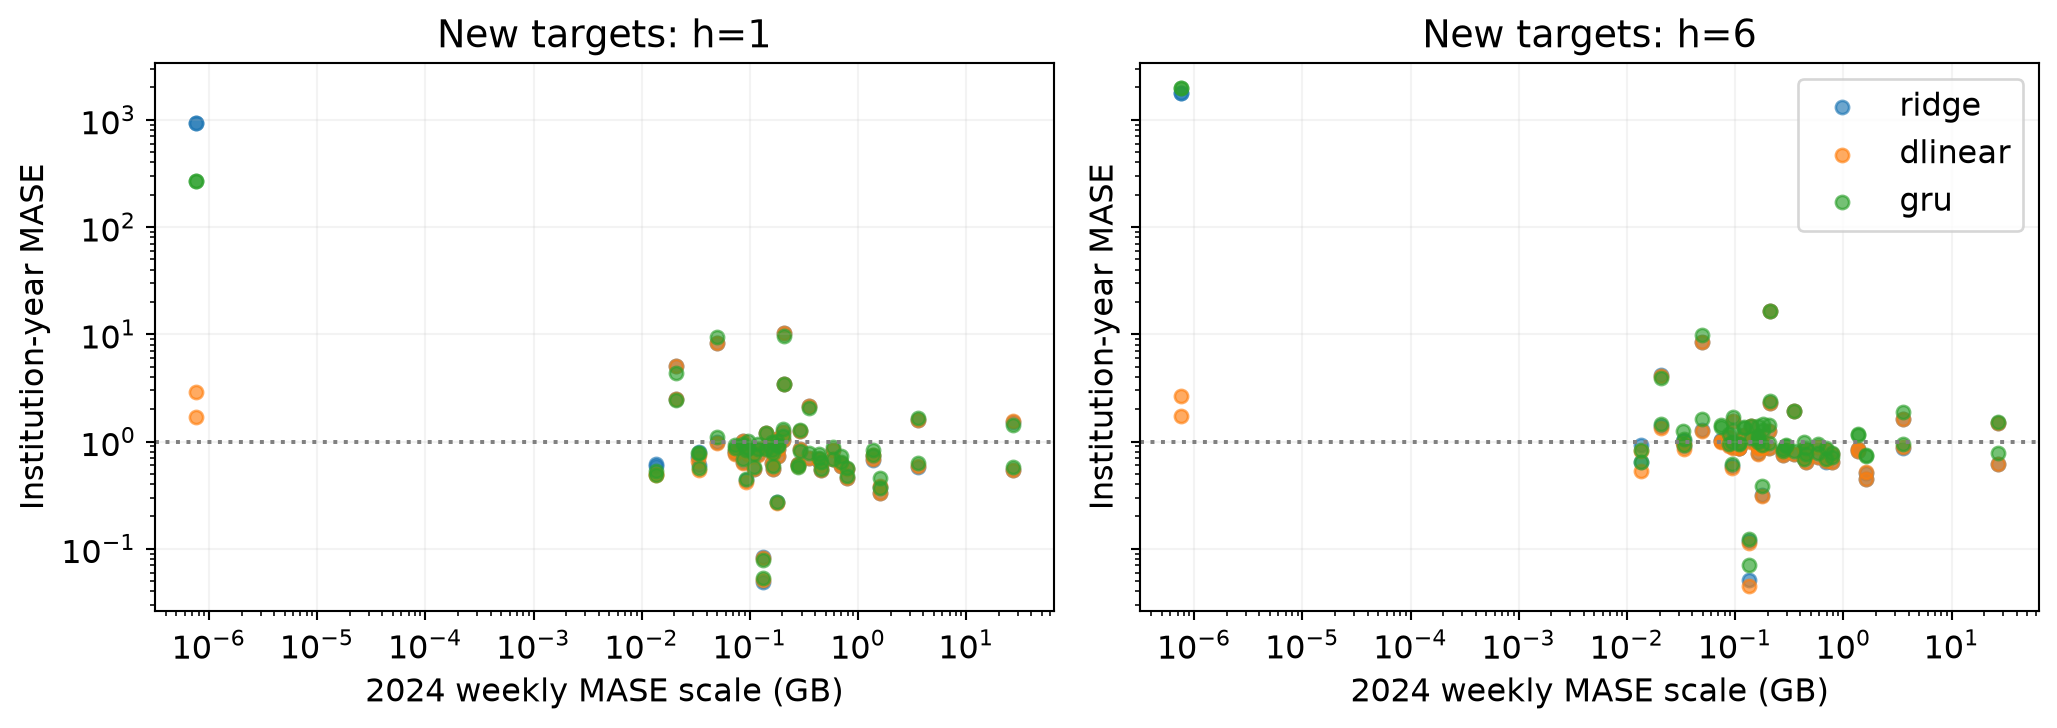

In [14]:
distribution=pd.read_csv(ROOT/'results/forecast_distribution_diagnostic.csv')
display(distribution)
display(readjson('FORECAST_DIAGNOSTICS.json'))
from IPython.display import Image
display(Image(filename=str(ROOT/'figures/replication_forecast_scales.png')))

## 6. Exact seven-day Shapley allocations
Seven groups represent the seven input days. Enumerating 128 coalitions gives exact Shapley values for the chosen replacement game. Efficiency is an arithmetic property, not evidence that the attribution is causal or operationally correct.

In [15]:
def games(model,x,r,bias=None):
 coal=r[None,:]+np.repeat(MASKS,24,axis=1)*(x-r)[None,:];v=model(coal,bias);phi=np.zeros((2,7))
 for j,(ix,w) in enumerate(SHAPLEY_WEIGHTS):phi[:,j]=np.sum((v[ix+(1<<j)]-v[ix])*w[:,None],axis=0)
 err=abs(phi.sum(1)-(v[-1]-v[0]));assert (err<=1e-8+1e-6*abs(v[-1]-v[0])).all()
 occ=abs(v[-1]-v[127-(1<<np.arange(7))]);return phi,occ.T,v,err

,h=1 allocation GB,h=6 allocation GB
day 1,0.057844,-0.043813
day 2,0.024151,0.014489
day 3,0.010508,0.035276
day 4,0.003515,0.002681
day 5,0.000236,-0.003137
day 6,-0.000455,-0.003561
day 7,-0.043643,-0.116659


Efficiency residual GB: [2.08166817e-17 2.77555756e-17]


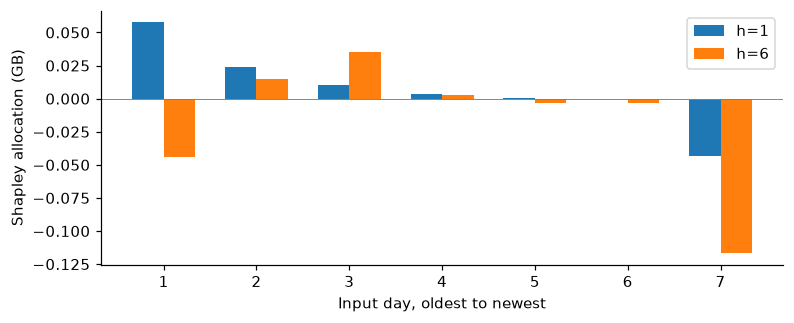

In [16]:
profile=np.load(ROOT/'models/source_profile.npy')
how=t.day_of_week.to_numpy()*24+t.hour.to_numpy();r=profile[how]
model=Predictor('gru',42)
phi,occ,values,eff=games(model,x,r)
display(pd.DataFrame(phi.T,columns=['h=1 allocation GB','h=6 allocation GB'],index=[f'day {i+1}' for i in range(7)]))
print('Efficiency residual GB:',eff)
fig,ax=plt.subplots(figsize=(8,3));ax.bar(np.arange(7)-.17,phi[0],.34,label='h=1');ax.bar(np.arange(7)+.17,phi[1],.34,label='h=6');ax.axhline(0,color='gray',lw=.6);ax.set(xticks=range(7),xticklabels=range(1,8),xlabel='Input day, oldest to newest',ylabel='Shapley allocation (GB)');ax.legend();plt.show()

## 7. Independent replacement operators and ranking utility
Interpolation and cyclic day rotation define controlled responses separately from the attribution reference. All 5,040 orders are enumerated to compute random-order and oracle utilities. Q=(U−R)/(O−R); it is undefined when the oracle gap is at most 1e−9 GB. Q can be negative and is not a probability.

In [17]:
def templates(x):
 b=x.reshape(7,24)
 return {'interpolation':np.stack([np.linspace(a[0],a[-1],24) for a in b]).ravel(),'rotation':np.roll(b,1,axis=0).ravel()}

def response_game(model,x,r,bias=None):
 # V indexes replaced (rather than retained) groups.
 a=x[None,:]+np.repeat(MASKS,24,axis=1)*(r-x)[None,:];v=model(a,bias)
 response=abs(v[REMOVED[:,1:]]-v[REMOVED[:,:-1]]);cum=np.cumsum(response,axis=1);utilities=cum[:,[0,1,3],:].mean(1)
 return v,utilities.mean(0),utilities.max(0)

def quality(v,rank,random,oracle):
 masks=np.r_[0,np.cumsum(1<<rank)];cpd=np.cumsum(abs(v[masks[1:]]-v[masks[:-1]]),axis=0);u=cpd[[0,1,3]].mean(0);gap=oracle-random
 q=np.divide(u-random,gap,out=np.full(2,np.nan),where=gap>1e-9)
 assert np.all(q[np.isfinite(q)]<=1.00001),q
 return u,q,gap

In [18]:
rows=[]
for op,tmp in templates(x).items():
    vv,random,oracle=response_game(model,x,tmp)
    for k,h in enumerate([1,6]):
        rank=order(abs(phi[k]),f'{id0}:{case.origin}:{h}')
        utility,q,gap=quality(vv,rank,random,oracle)
        rows.append(dict(operator=op,horizon=h,quality_q=q[k],utility_gb=utility[k],oracle_gap_gb=gap[k]))
display(pd.DataFrame(rows))

,operator,horizon,quality_q,utility_gb,oracle_gap_gb
0,interpolation,1,0.841353,0.076389,0.032554
1,interpolation,6,0.707972,0.124870,0.052667
2,rotation,1,0.884852,0.076389,0.042601
3,rotation,6,0.414961,0.091807,0.058949


## 8. Integrated gradients: retain numerical failures
Quadrature increases from 32 to 512 nodes. Acceptance requires both completeness and refinement tolerances. Rejected cases are retained in the numerical audit and excluded from accepted-IG ranking scores.

In [19]:
def integrated_gradients(model,x,r):
 delta=x-r;prev=None;accepted=np.zeros(2,bool);answer=np.zeros((2,168));steps=np.zeros(2,int);errors=np.zeros(2);lastchange=np.zeros(2)
 contrast=model(x)-model(r)
 for n,(ab,w) in NODES.items():
  alpha=(ab+1)/2;ww=w/2;current=np.zeros((2,168))
  for a in range(0,n,64):
   raw=r[None,:]+alpha[a:a+64,None]*delta[None,:];p=torch.tensor(raw,dtype=torch.float64,requires_grad=True);z=model.net(p)
   for k in range(2):
    grad=torch.autograd.grad(z[:,k].sum(),p,retain_graph=k==0)[0].detach().numpy();current[k]+=np.sum(ww[a:a+64,None]*grad,axis=0)*delta
  err=abs(current.sum(1)-contrast)
  if prev is not None:
   change=abs(current-prev).sum(1);ok=(err<=1e-8+1e-3*abs(contrast))&(change<=1e-8+1e-3*abs(current).sum(1));new=ok&~accepted
   answer[new]=current[new];steps[new]=n;errors[new]=err[new];lastchange[new]=change[new];accepted|=ok
  prev=current
  if accepted.all():break
 remaining=~accepted;answer[remaining]=current[remaining];steps[remaining]=n;errors[remaining]=err[remaining];lastchange[remaining]=change[remaining]
 return answer.reshape(2,7,24).sum(2),accepted,steps,errors,lastchange

In [20]:
ig,accepted,steps,error,change=integrated_gradients(model,x,r)
display(pd.DataFrame({'horizon':[1,6],'accepted':accepted,'nodes':steps,'completeness_error_gb':error,'L1_refinement_gb':change}))
display(pd.read_csv(ROOT/'results/ig_numerical_summary.csv'))

,horizon,accepted,nodes,completeness_error_gb,L1_refinement_gb
0,1,True,64,1.387779e-17,3.421505e-16
1,6,True,64,2.359224e-16,7.143043e-16


,model,reference,horizon,cases,accepted,max_completeness_error_gb
0,dlinear,history_hour_median,1,1512,1441,0.000162
1,dlinear,history_hour_median,6,1512,1436,0.000405
2,dlinear,source_calendar,1,1512,1406,0.000402
3,dlinear,source_calendar,6,1512,1418,0.000258
4,gru,history_hour_median,1,1512,1462,11.003852
5,gru,history_hour_median,6,1512,1427,37.612251
6,gru,source_calendar,1,1512,1479,0.950428
7,gru,source_calendar,6,1512,1437,0.124765
8,ridge,history_hour_median,1,504,476,0.000115
9,ridge,history_hour_median,6,504,476,0.000097


## 9. Effective denominators and missingness
More response queries do not create more independent institutions. Undefined Q and failed IG need explicit denominators. Outcome-dependent availability limits the population to which complete-case estimates apply.

In [21]:
exclusions=pd.read_csv(ROOT/'results/quality_exclusions.csv')
display(exclusions)
g=exclusions.query("arm=='frozen' and reference=='source_calendar' and method=='shapley'").groupby(['model','cohort'])[['records','defined']].sum()
g['defined_fraction']=g.defined/g.records;display(g)

,model,cohort,year,arm,horizon,reference,method,operator,records,defined,discriminating,accepted
0,dlinear,source,2025,calibrated,1,history_hour_median,occlusion,interpolation,1536,1449,1449,1536
1,dlinear,source,2025,calibrated,1,history_hour_median,occlusion,rotation,1536,1450,1450,1536
2,dlinear,source,2025,calibrated,1,history_hour_median,recency,interpolation,1536,1449,1449,1536
3,dlinear,source,2025,calibrated,1,history_hour_median,recency,rotation,1536,1450,1450,1536
4,dlinear,source,2025,calibrated,1,history_hour_median,shapley,interpolation,1536,1449,1449,1536
...,...,...,...,...,...,...,...,...,...,...,...,...
667,ridge,target,2026,frozen,6,source_calendar,occlusion,rotation,496,494,494,496
668,ridge,target,2026,frozen,6,source_calendar,recency,interpolation,496,496,496,496
669,ridge,target,2026,frozen,6,source_calendar,recency,rotation,496,494,494,496
670,ridge,target,2026,frozen,6,source_calendar,shapley,interpolation,496,496,496,496


records  defined  defined_fraction
model   cohort                                    
dlinear source    12096    11527          0.952960
        target    12096    11475          0.948661
gru     source    12096    11482          0.949239
        target    12096    11502          0.950893
ridge   source     4032     4023          0.997768
        target     4032     4018          0.996528

## 10. Primary paired transfer contrast
Seeds are averaged only with a complete seed set; source and target must share an origin. Equal weighting across two years and two operators precedes equal weighting across complete institution pairs. Independent inference units are institutions, not response queries.

Complete pairs: 30 independent point: -0.007535076243646839


year              2025                    2026          
operator interpolation  rotation interpolation  rotation
pair                                                    
0            -0.040877  0.043544      0.167745  0.170827
2            -0.242753  0.041927     -0.160846 -0.096535
3            -0.072581  0.113321     -0.075368  0.182182
5            -0.215395 -0.231086     -0.011117 -0.224882
6             0.108383  0.184431      0.068314  0.182828
7            -0.035549  0.118616     -0.055118  0.113874
8             0.180698 -0.016520     -0.004080  0.120148
9             0.118915 -0.137506     -0.283713 -0.090981
10            0.048462 -0.167730      0.084479 -0.105581
11           -0.111228 -0.044621      0.039597  0.080635
12            0.007776 -0.096058      0.071487  0.028248
13           -0.025387  0.026857      0.099804  0.039818
14           -0.048281 -0.001145      0.066082 -0.177390
15           -0.136925 -0.140308      0.082913  0.053745
16            0.138998 -0.071273      0.036873 -0.025148
17           -0.016319  0.005593     -0.095722 -0.168176
18           -0.097805 -0.160997     -0.039487 -0.103819
19            0.057029  0.108600      0.009980  0.116676
20            0.072563 -0.052203     -0.096212 -0.066037
21           -0.112556 -0.017477     -0.081735  0.059239
22            0.112338 -0.006158      0.113684 -0.018733
23           -0.050083  0.021583      0.126538 -0.045012
24            0.107383 -0.391091     -0.098296 -0.244642
25           -0.068933  0.151533     -0.045126  0.009281
26            0.004780 -0.035872     -0.151290 -0.099051
27            0.044129  0.057959      0.062882 -0.076279
28           -0.152981  0.012416     -0.124768  0.015002
29            0.195214  0.022488      0.142720 -0.122697
30            0.294002 -0.029913      0.369042 -0.105656
31            0.167263  0.016736      0.034353 -0.115637

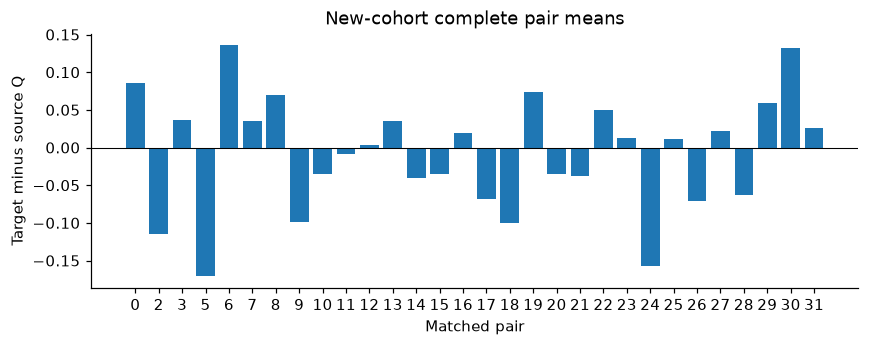

In [22]:
paired=pd.read_csv(ROOT/'results/paired_quality.csv.gz')
primary=paired.query("model=='gru' and arm=='frozen' and horizon==1 and reference=='source_calendar' and method=='shapley'").copy()
cells=primary.groupby(['pair','year','operator']).delta.mean().unstack(['year','operator'])
complete_cells=cells.dropna()
independent_point=complete_cells.mean(axis=1).mean()
print('Complete pairs:',len(complete_cells),'independent point:',independent_point)
display(complete_cells)
fig,ax=plt.subplots(figsize=(9,3));ax.bar(complete_cells.index.astype(str),complete_cells.mean(axis=1));ax.axhline(0,color='black',lw=.7);ax.set(xlabel='Matched pair',ylabel='Target minus source Q',title='New-cohort complete pair means');plt.show()

## 11. Prespecified bootstrap and interval failure
The original pair/within-pair block bootstrap attempts exactly 2,000 draws. An interval requires at least four complete pairs and 1,000 valid draws. A missing interval is a failed inferential procedure; it is not evidence of no effect. No additional attempts are added after seeing the valid count.

In [23]:
def bootstrap(frame,B=2000):
 # frame: one matched source/target contrast per origin/operator after seed averaging.
 f=frame.copy();f['block']=(pd.to_datetime(f.origin,utc=True)-pd.to_datetime(f.year.astype(str)+'-04-08',utc=True)).dt.days//14
 cells=f.groupby(['pair','year','operator']).size();good=[p for p in f.pair.unique() if len(cells.loc[p])==4]
 f=f[f.pair.isin(good)];point=float(f.groupby(['pair','year','operator']).delta.mean().groupby('pair').mean().mean()) if len(f) else None
 if len(good)<4:return dict(mean=point,ci_low=None,ci_high=None,pairs=len(good),bootstrap_valid=0,reason='fewer_than_four_complete_pairs')
 arrays={}
 for p in good:
  arrays[p]={}
  for year in [2025,2026]:
   g=f[(f.pair==p)&(f.year==year)];blocks=sorted(g.block.unique());a=g.groupby(['block','operator']).delta.agg(['sum','count']).unstack('operator').reindex(blocks).fillna(0)
   arrays[p][year]=(a['sum'].reindex(columns=['interpolation','rotation']).to_numpy(),a['count'].reindex(columns=['interpolation','rotation']).to_numpy())
 rng=np.random.default_rng(20261105);vals=[]
 for _ in range(B):
  pair_stats=[];valid=True
  for p in rng.choice(good,len(good),replace=True):
   means=[]
   for year in [2025,2026]:
    sums,counts=arrays[p][year];ix=rng.integers(len(sums),size=len(sums));den=counts[ix].sum(0)
    if (den==0).any():valid=False;break
    means.extend((sums[ix].sum(0)/den).tolist())
   if not valid:break
   pair_stats.append(np.mean(means))
  if valid:vals.append(np.mean(pair_stats))
 return dict(mean=point,ci_low=float(np.quantile(vals,.025)) if len(vals)>=1000 else None,ci_high=float(np.quantile(vals,.975)) if len(vals)>=1000 else None,pairs=len(good),bootstrap_valid=len(vals),reason='nominal_paired_pair_and_14day_block_bootstrap')

In [24]:
sensitivity=readjson('SENSITIVITY_RESULTS.json')
primary_report=sensitivity['main_original_pair_block']
assert np.isclose(independent_point,primary_report['mean'],rtol=0,atol=1e-12)
display(primary_report)
recomputed_primary=bootstrap(primary)
for k in ['mean','ci_low','ci_high']:assert np.isclose(recomputed_primary[k],primary_report[k],rtol=0,atol=1e-12)
assert recomputed_primary['bootstrap_valid']==primary_report['bootstrap_valid']
print('Recomputed all 2000 primary bootstrap attempts:',recomputed_primary)

{'mean': -0.007535076243646839,
 'ci_low': -0.040152857932414986,
 'ci_high': 0.024125086196251984,
 'pairs': 30,
 'bootstrap_valid': 1885,
 'reason': 'nominal_paired_pair_and_14day_block_bootstrap'}

Recomputed all 2000 primary bootstrap attempts: {'mean': -0.007535076243646839, 'ci_low': -0.040152857932414986, 'ci_high': 0.024125086196251984, 'pairs': 30, 'bootstrap_valid': 1885, 'reason': 'nominal_paired_pair_and_14day_block_bootstrap'}


## 12. Additional uncertainty analyses
Pair-only resampling conditions on the observed periods. Synchronized calendar-block resampling keeps common blocks across institutions. Both were specified before scoring, but remain sensitivity analyses and cannot replace a failed primary interval.

In [25]:
def complete(frame):
 cells=frame.groupby(['pair','year','operator']).delta.mean().unstack(['year','operator']);good=cells.dropna().index.tolist();return frame[frame['pair'].isin(good)].copy(),cells.loc[good].mean(1)

def sensitivities(frame,B=2000):
 f,pairmeans=complete(frame);good=pairmeans.index.to_numpy();point=float(pairmeans.mean()) if len(good) else None
 if len(good)<4:return dict(pair_only=dict(mean=point,ci_low=None,ci_high=None,pairs=len(good),reason='fewer_than_four_pairs'),synchronized_blocks=dict(mean=point,ci_low=None,ci_high=None,pairs=len(good),bootstrap_valid=0,reason='fewer_than_four_pairs'))
 rng=np.random.default_rng(20261106);means=pairmeans.to_numpy();vals=means[rng.integers(len(means),size=(B,len(means)))].mean(1)
 paironly=dict(mean=point,ci_low=float(np.quantile(vals,.025)),ci_high=float(np.quantile(vals,.975)),pairs=len(good),bootstrap_valid=B,reason='pair_cluster_only_conditional_on_observed_periods')
 f['block']=(pd.to_datetime(f.origin,utc=True)-pd.to_datetime(f.year.astype(str)+'-04-08',utc=True)).dt.days//14;arrays={}
 for p in good:
  arrays[int(p)]={}
  for year in [2025,2026]:
   a=f[(f['pair']==p)&(f.year==year)].groupby(['block','operator']).delta.agg(['sum','count']).unstack('operator').reindex(range(6)).fillna(0)
   arrays[int(p)][year]=(a['sum'].reindex(columns=['interpolation','rotation']).fillna(0).to_numpy(),a['count'].reindex(columns=['interpolation','rotation']).fillna(0).to_numpy())
 rng=np.random.default_rng(20261106);values=[]
 for _ in range(B):
  chosen=rng.choice(good,len(good),replace=True);blocks={y:rng.integers(6,size=6) for y in [2025,2026]};stats=[];valid=True
  for p in chosen:
   v=[]
   for year in [2025,2026]:
    sums,counts=arrays[int(p)][year];ix=blocks[year];den=counts[ix].sum(0)
    if (den==0).any():valid=False;break
    v.extend((sums[ix].sum(0)/den).tolist())
   if not valid:break
   stats.append(np.mean(v))
  if valid:values.append(np.mean(stats))
 sync=dict(mean=point,ci_low=float(np.quantile(values,.025)) if len(values)>=1000 else None,ci_high=float(np.quantile(values,.975)) if len(values)>=1000 else None,pairs=len(good),bootstrap_valid=len(values),bootstrap_attempted=B,reason='synchronized_six_calendar_blocks_per_year')
 return dict(pair_only=paironly,synchronized_blocks=sync)

In [26]:
display(sensitivity['main_sensitivity'])
print('Reused-case equality audit:',{k:v for k,v in sensitivity.items() if 'intersection' in k or 'reused_' in k})

{'pair_only': {'mean': -0.007535076243646839,
  'ci_low': -0.0350306376566534,
  'ci_high': 0.01882818899889661,
  'pairs': 30,
  'bootstrap_valid': 2000,
  'reason': 'pair_cluster_only_conditional_on_observed_periods'},
 'synchronized_blocks': {'mean': -0.007535076243646839,
  'ci_low': -0.04221782215579705,
  'ci_high': 0.03131155394329124,
  'pairs': 30,
  'bootstrap_valid': 1872,
  'bootstrap_attempted': 2000,
  'reason': 'synchronized_six_calendar_blocks_per_year'}}

Reused-case equality audit: {'dense_main_intersection_exact': True, 'reused_operator_seed_records': 72576}


## 13. Nested 16-to-64-origin comparison
Dense evaluation retains the original 16 origins, adds up to 48, and reuses their already computed rows. It uses frozen GRU checkpoints, source-calendar Shapley/occlusion/recency, no additional fitting and no dense IG. Compare both native and common-complete-pair panels; denominator changes can change the estimand.

,0,1
horizon,1,6
main_pairs,30,30
dense_pairs,30,30
common_pairs,30,30
main_original_pair_block.mean,-0.007535,-0.003403
main_original_pair_block.ci_low,-0.040153,-0.041669
main_original_pair_block.ci_high,0.024125,0.031406
main_original_pair_block.pairs,30,30
main_original_pair_block.bootstrap_valid,1885,1981
main_original_pair_block.reason,nominal_paired_pair_and_14day_block_bootstrap,nominal_paired_pair_and_14day_block_bootstrap


,horizon,analysis,mean,ci_low,ci_high,pairs,bootstrap_valid,reason
0,1,main_original_pair_block,-0.007535,-0.040153,0.024125,30,1885,nominal_paired_pair_and_14day_block_bootstrap
1,1,dense_original_pair_block,0.000137,-0.022940,0.024817,30,2000,nominal_paired_pair_and_14day_block_bootstrap
2,1,common_pair_main,-0.007535,-0.040153,0.024125,30,1885,nominal_paired_pair_and_14day_block_bootstrap
3,1,common_pair_dense,0.000137,-0.022940,0.024817,30,2000,nominal_paired_pair_and_14day_block_bootstrap
4,6,main_original_pair_block,-0.003403,-0.041669,0.031406,30,1981,nominal_paired_pair_and_14day_block_bootstrap
5,6,dense_original_pair_block,-0.019710,-0.053353,0.008977,30,1988,nominal_paired_pair_and_14day_block_bootstrap
6,6,common_pair_main,-0.003403,-0.041669,0.031406,30,1981,nominal_paired_pair_and_14day_block_bootstrap
7,6,common_pair_dense,-0.019710,-0.053353,0.008977,30,1988,nominal_paired_pair_and_14day_block_bootstrap


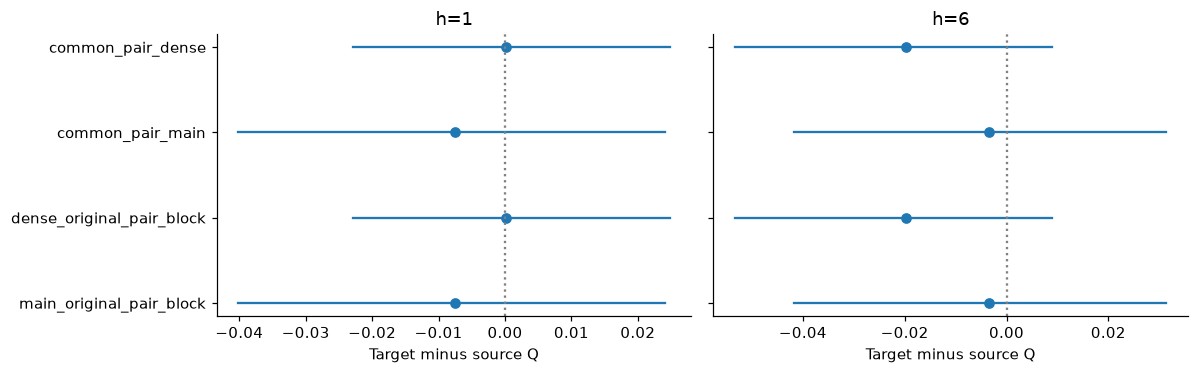

In [27]:
budget=sensitivity['dense_budget_comparison']
display(pd.json_normalize(budget).T)
rows=[]
for item in budget:
    for key in ['main_original_pair_block','dense_original_pair_block','common_pair_main','common_pair_dense']:
        rows.append(dict(horizon=item['horizon'],analysis=key,**item[key]))
comparison=pd.DataFrame(rows);display(comparison)
fig,axes=plt.subplots(1,2,figsize=(11,3.5),sharey=True)
for ax,(h,g) in zip(axes,comparison.groupby('horizon')):
    ax.scatter(g['mean'],range(len(g)))
    for y,row in enumerate(g.itertuples()):
        if pd.notna(row.ci_low):ax.plot([row.ci_low,row.ci_high],[y,y],color='C0')
    ax.set(yticks=range(len(g)),yticklabels=g.analysis,title=f'h={h}',xlabel='Target minus source Q');ax.axvline(0,color='gray',ls=':')
plt.tight_layout();plt.show()

## 14. Secondary analyses
References, horizons, models and calibration arms answer distinct questions. These contrasts are descriptive or secondary; no significant-looking contrast is promoted to primary.

In [28]:
display(pd.read_csv(ROOT/'results/secondary_quality_contrasts.csv'))
print('Available analysis tables:')
print('\n'.join(p.name for p in sorted((ROOT/'results').glob('*.csv'))))

,model,horizon,reference,mean,ci_low,ci_high,pairs,bootstrap_valid,reason
0,dlinear,1,history_hour_median,0.004976,-0.038542,0.050345,30,1915,nominal_paired_pair_and_14day_block_bootstrap
1,dlinear,1,source_calendar,0.030912,-0.017451,0.074157,30,1915,nominal_paired_pair_and_14day_block_bootstrap
2,dlinear,6,history_hour_median,-0.003580,-0.045345,0.039512,30,2000,nominal_paired_pair_and_14day_block_bootstrap
3,dlinear,6,source_calendar,-0.002246,-0.039051,0.035211,30,2000,nominal_paired_pair_and_14day_block_bootstrap
4,gru,1,history_hour_median,-0.000220,-0.039061,0.037904,30,1885,nominal_paired_pair_and_14day_block_bootstrap
5,gru,1,source_calendar,-0.007535,-0.040153,0.024125,30,1885,nominal_paired_pair_and_14day_block_bootstrap
6,gru,6,history_hour_median,-0.010822,-0.052139,0.032612,30,1981,nominal_paired_pair_and_14day_block_bootstrap
7,gru,6,source_calendar,-0.003403,-0.041669,0.031406,30,1981,nominal_paired_pair_and_14day_block_bootstrap
8,ridge,1,history_hour_median,0.011890,-0.031957,0.054875,31,2000,nominal_paired_pair_and_14day_block_bootstrap
9,ridge,1,source_calendar,0.037475,-0.003073,0.076051,31,2000,nominal_paired_pair_and_14day_block_bootstrap


Available analysis tables:
AVAILABILITY.csv
SELECTION_DENSE_FROZEN.csv
SELECTION_MAIN_FROZEN.csv
calibration_offsets.csv
dense_denominators_by_stratum.csv
explanation_selection.csv
forecast_distribution_diagnostic.csv
forecast_equal_institution_macro.csv
forecast_extreme_cells.csv
forecast_institution_macro.csv
forecast_macro.csv
forecast_metrics.csv
forecast_per_year_macro.csv
ig_numerical_summary.csv
ig_numerics_dlinear_123.csv
ig_numerics_dlinear_2026.csv
ig_numerics_dlinear_42.csv
ig_numerics_gru_123.csv
ig_numerics_gru_2026.csv
ig_numerics_gru_42.csv
ig_numerics_ridge_0.csv
main_denominators_by_stratum.csv
primary_pair_operator.csv
quality_exclusions.csv
quality_institution_macro.csv
secondary_quality_contrasts.csv


## 15. Validation and computational workload
Hashes protect the frozen inputs, model bytes and scientific code. Audit files separately test numerical arithmetic, saved outputs and independent calculations. A short training run can be valid for compact models; data and institution counts, coverage and effective sample size matter more than elapsed time alone.

In [29]:
display(readjson('FINAL_VALIDATION.json'))
display(readjson('DENSE_COMPLETE.json'))
for name in ['DENSE_VALIDATION.json','REPLICATION_COMPLETION.json']:
    if (ROOT/'results'/name).exists():display(readjson(name))

{'status': 'pass',
 'checks': {'PREEVALUATION_FREEZE': True,
  '64_data_hashes': True,
  'model_hashes': True,
  'disjoint_membership': True,
  'forecast_metric_recalculation': True,
  'checkpoint_prediction_and_truth_requeries': True,
  'permutation_shapley_oracle': True,
  'ranking_quality_requeries': True,
  'primary_point_independent': True,
  'failed_ig_never_scored': True},
 'details': {'prediction_rows': 1108120,
  'max_metric_difference': 0.0,
  'max_prediction_difference': 1.4210854715202004e-13,
  'max_shapley_difference': 7.244205235679146e-15,
  'max_quality_difference': 0.0,
  'selection_by_pair_year': [{'pair': 0,
    'year': 2025,
    'selected': 32,
    'common_eligible': 307},
   {'pair': 0, 'year': 2026, 'selected': 32, 'common_eligible': 129},
   {'pair': 1, 'year': 2025, 'selected': 32, 'common_eligible': 307},
   {'pair': 2, 'year': 2025, 'selected': 32, 'common_eligible': 307},
   {'pair': 2, 'year': 2026, 'selected': 32, 'common_eligible': 129},
   {'pair': 3, 'y

{'status': 'complete',
 'runtime_seconds': 975.4202169589698,
 'models': [{'seed': 42,
   'main_score_rows': 24192,
   'added_score_rows': 72576,
   'all_score_rows': 96768,
   'added_histories': 6048},
  {'seed': 123,
   'main_score_rows': 24192,
   'added_score_rows': 72576,
   'all_score_rows': 96768,
   'added_histories': 6048},
  {'seed': 2026,
   'main_score_rows': 24192,
   'added_score_rows': 72576,
   'all_score_rows': 96768,
   'added_histories': 6048}],
 'dense_planned_histories': 8064,
 'main_histories_reused': 2016,
 'new_target_outcomes_scored': True}

{'status': 'pass',
 'checks': {'frozen_100_input_hashes': True,
  'main_plan_nested': True,
  'frozen_plan_equals_evaluated_main': True,
  'dense_record_count': True,
  'dense_case_plan_exact': True,
  'reused_cases_preserved': True,
  'added_case_nan_status': True,
  'added_case_requeries': True,
  'dense_primary_point_independent': True},
 'details': {'main_roundtrip_max_abs_difference': 0.0,
  'added_queries': 16,
  'max_added_query_difference': 0.0,
  'dense_h1_point_independent': 0.00013741007922235922,
  'dense_h1_complete_pairs': 30},
 'post_evaluation_audit': True}

{'status': 'complete',
 'completed_utc': '2026-11-06T19:22:14.692306+00:00',
 'new_target_institutions': 32,
 'new_targets_disjoint_from_all_original_institutions': True,
 'total_unique_institutions_both_studies': 80,
 'source_anchors_reused': True,
 'source_models_refitted': False,
 'independent_network_replication': False,
 'primary': {'mean': -0.007535076243646839,
  'ci_low': -0.040152857932414986,
  'ci_high': 0.024125086196251984,
  'pairs': 30,
  'bootstrap_valid': 1885,
  'reason': 'nominal_paired_pair_and_14day_block_bootstrap'},
 'main_quality_records': 705600,
 'main_ig_cases': 14112,
 'main_ig_failed': 690,
 'prediction_rows': 1108120,
 'main_xai_seconds': 1121.4363071918488,
 'forecast_seconds': 14.960535049438477,
 'dense_xai_seconds': 975.4202169589698,
 'notebook': {'status': 'pass',
  'runtime_seconds': 3.5333790840231813,
  'cells': 52,
  'code_cells': 31,
  'executed_code_cells': 31,
  'embedded_pngs': 7,
  'errors': 0,
  'kernel': 'xai-project',
  'input_notebook_sh

## 15b. Focused post-hoc conference checks
These analyses were specified after the original and new-cohort outcomes, then locally frozen before randomized-model outcomes. They preserve the two primary estimands. GRU h1/source-calendar is the limited scope. Read `conference_checks/PLAN.md` for the exact masks, seeds, metrics and conditional interpretation.

In [30]:
CHECKS=ROOT/'conference_checks'
comparison=json.loads((CHECKS/'results/EXPLAINER_COMPARISON.json').read_text())
display(pd.read_csv(CHECKS/'results/method_table.csv',header=[0,1],index_col=0))
display(pd.DataFrame(json.loads((CHECKS/'results/DENOMINATOR_CLARIFICATIONS.json').read_text())['counts']))
print('Exact random-order mean Q = 0 on informative response games. Cross-panel means use different populations.')

panel             A                   B          
cohort       source    target    source    target
method                                           
shapley    0.694108  0.690155  0.681847  0.700359
ig              NaN       NaN  0.681548  0.704602
occlusion  0.690823  0.686891  0.681338  0.703807
recency    0.541484  0.533451  0.453984  0.466061

,panel,cohort,common_cases_before_complete_operator_cell,used_history_operator_cases,histories_used,institution_years_used
0,A,source,1813,1813,929,61
1,A,target,1824,1824,936,61
2,B,source,451,451,228,61
3,B,target,452,451,227,60


Exact random-order mean Q = 0 on informative response games. Cross-panel means use different populations.


### Reconstruct the common-case absolute means
All required methods must have three defined seeds on identical cases. Panel A uses the main budget; panel B uses the original IG subset and accepted IG. Both operators are required within each retained institution-year. These available-period means are different from the complete-pair primary contrast.

In [31]:
saved=pd.read_csv(CHECKS/'results/explainer_macro.csv')
for panel,methods in [('A',['shapley','occlusion','recency']),('B',['shapley','ig','occlusion','recency'])]:
    common=pd.read_csv(CHECKS/f'results/common_cases_{panel}.csv.gz')
    cells=common.groupby(['id','cohort','year','operator'])[methods].mean().unstack('operator')
    cells=cells.dropna()
    years=pd.DataFrame({m:cells[m][['interpolation','rotation']].mean(axis=1) for m in methods}).reset_index()
    institutions=years.groupby(['id','cohort'])[methods].mean().reset_index()
    means=institutions.groupby('cohort')[methods].mean()
    for cohort in ['source','target']:
        for m in methods:
            expected=saved.query('panel==@panel and cohort==@cohort and method==@m').quality_q.iloc[0]
            assert np.isclose(means.loc[cohort,m],expected,atol=1e-12,rtol=0)
    display(means)
print('Both panels independently reconstructed.')

,shapley,occlusion,recency
cohort,,,
source,0.694108,0.690823,0.541484
target,0.690155,0.686891,0.533451


,shapley,ig,occlusion,recency
cohort,,,,
source,0.681847,0.681548,0.681338,0.453984
target,0.700359,0.704602,0.703807,0.466061


Both panels independently reconstructed.


### Cascading learned-layer parameter sensitivity
The fixed control uses 126 timestamp-selected histories, three trained seeds and three reset replicates. Reset head, then GRU while keeping the same randomized head. The source buffers, reference, log/clipping/output and fixed last-input residual route remain. No threshold defines a pass. Comparisons condition on nonflat patterns common to both stages, with exclusions retained.

In [32]:
import copy
from scipy.stats import spearmanr
EPS=1e-9
def pattern_metrics(a,b):
 la=float(abs(a).sum());lb=float(abs(b).sum());defined=la>EPS and lb>EPS
 distance=float(.5*abs(a/la-b/lb).sum()) if defined else np.nan
 rho=float(spearmanr(abs(a),abs(b)).statistic) if defined and np.ptp(abs(a))>0 and np.ptp(abs(b))>0 else np.nan
 return distance,rho,la,lb

def randomize(base,seed,replicate):
 hseed=seed*10000+replicate
 head=copy.deepcopy(base)
 with torch.random.fork_rng():torch.manual_seed(hseed);head.net.head.reset_parameters()
 full=copy.deepcopy(head)
 with torch.random.fork_rng():torch.manual_seed(hseed+100000000);full.net.gru.reset_parameters()
 return head,full

In [33]:
# Actually regenerate one predeclared randomized model pair and verify saved tensors.
head_control,full_control=randomize(Predictor('gru',42),42,701)
for stage,net in [('head',head_control),('head_gru',full_control)]:
    checkpoint=torch.load(CHECKS/f'models/{stage}_42_701.pt',weights_only=True,map_location='cpu')
    assert all(torch.equal(net.net.state_dict()[k],v) for k,v in checkpoint['state'].items())
print('Head and cumulative GRU resets reproduce exactly; no fitting ran.')
task=pd.read_csv(CHECKS/'case_plan.csv').sort_values(['pair','year','cohort','origin']).iloc[0]
cv=windows(ROOT/f'data/institution_{int(task.id)}.csv.gz');co=int(cv['t'].get_loc(pd.Timestamp(task.origin)))
cx=cv['y'][co-167:co+1];ct=cv['t'][co-167:co+1];cr=profile[ct.day_of_week*24+ct.hour]
trained_phi,*_=games(Predictor('gru',42),cx,cr)
random_phi,*_=games(full_control,cx,cr)
distance,rho,_,_=pattern_metrics(trained_phi[0],random_phi[0])
records=pd.read_csv(CHECKS/'results/parameter_records.csv.gz')
record=records.query('id==@task.id and year==@task.year and origin==@task.origin and seed==42 and replicate==701 and stage=="head_gru"').iloc[0]
assert np.isclose(distance,record.pattern_distance,atol=1e-12,equal_nan=True)
assert np.isclose(rho,record.rank_spearman,atol=1e-12,equal_nan=True)
print({'fixed_first_case_pattern_distance':distance,'rank_similarity':rho,'flat_cases_stay_undefined':True})

Head and cumulative GRU resets reproduce exactly; no fitting ran.
{'fixed_first_case_pattern_distance': nan, 'rank_similarity': nan, 'flat_cases_stay_undefined': True}


,metric,cohort,stage,mean_equal_institutions,median_institution,institutions,common_comparison_records,common_histories,planned_comparison_records,stage_metric_defined,trained_nonflat,randomized_nonflat,randomized_clipped
0,pattern_distance,source,head,0.619596,0.696792,32,337,63,567,425,567,425,203
1,pattern_distance,source,head_gru,0.570058,0.454514,32,337,63,567,342,567,342,225
2,pattern_distance,target,head,0.564894,0.598494,32,364,63,567,439,567,439,167
3,pattern_distance,target,head_gru,0.531174,0.454620,32,364,63,567,367,567,367,201
4,rank_spearman,source,head,0.716218,0.733383,32,337,63,567,425,567,425,203
5,rank_spearman,source,head_gru,0.119054,0.054637,32,337,63,567,342,567,342,225
6,rank_spearman,target,head,0.718532,0.718750,32,364,63,567,439,567,439,167
7,rank_spearman,target,head_gru,0.161740,0.145096,32,364,63,567,367,567,367,201


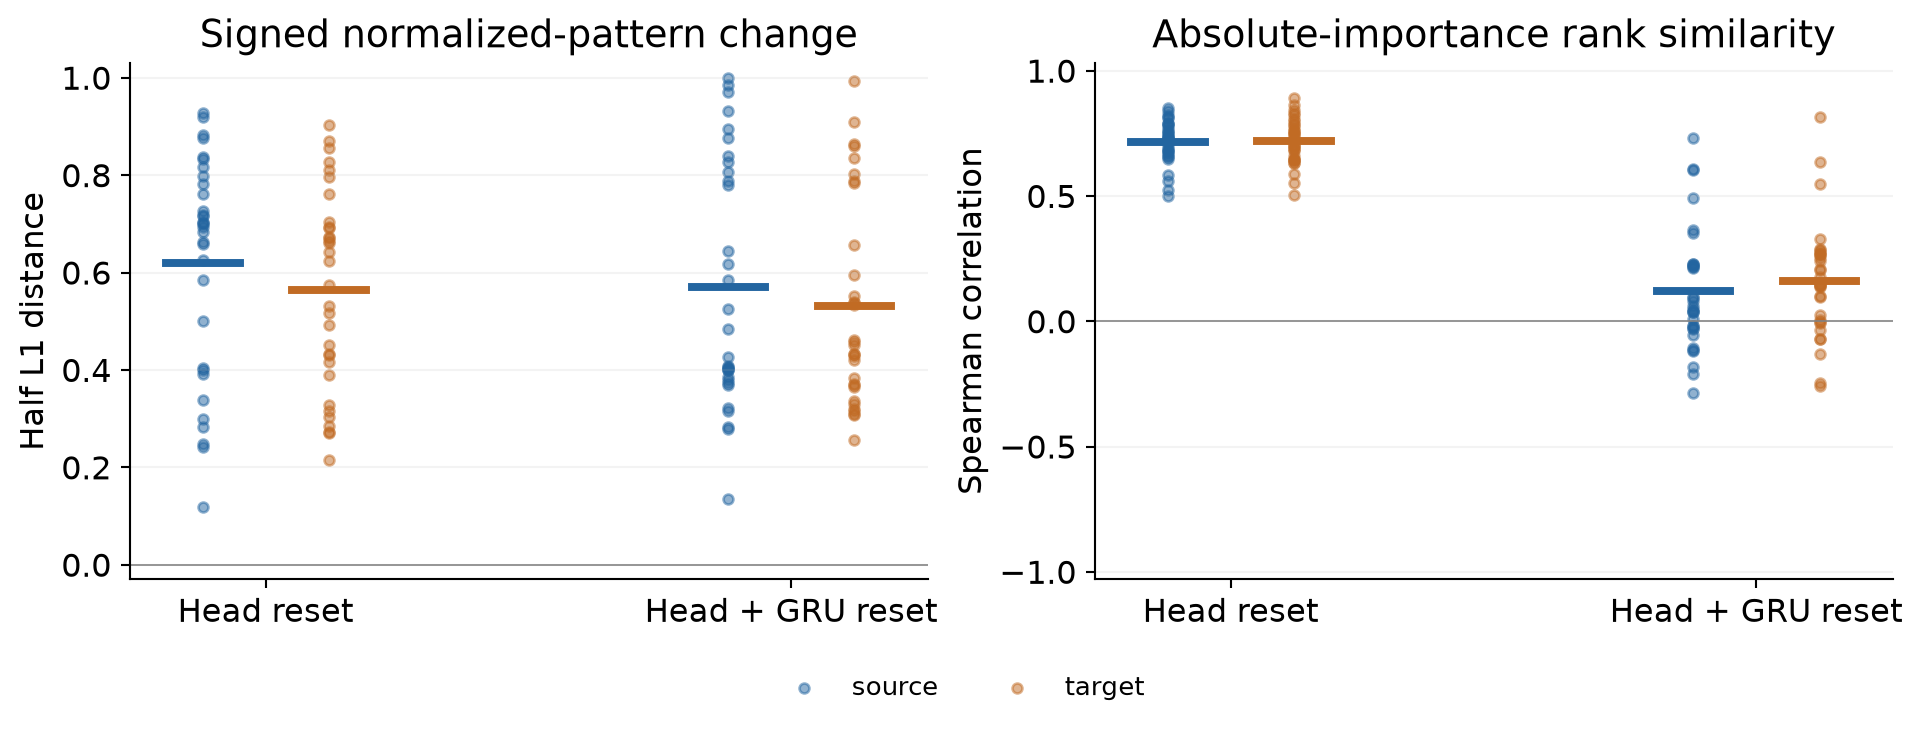

{'status': 'pass',
 'checks': {'extension_frozen_files': True,
  'upstream_frozen_files': True,
  'original_quality_inputs': True,
  'panel_A_complete_values': True,
  'panel_B_complete_values': True,
  'independent_explainer_macro': True,
  'complete_control_grid': True,
  'finite_nonnegative_predictions': True,
  'pattern_distance_bounds': True,
  'pattern_distance_recalculation': True,
  'randomized_checkpoint_requeries': True,
  'permutation_shapley_check': True,
  'copied_model_identity': True,
  'same_random_head_across_stages': True,
  'preserved_source_buffers': True,
  'retained_fixed_residual_architecture': True},
 'details': {'max_explainer_macro_difference': 1.1102230246251565e-16,
  'max_pattern_distance_difference': 0.0,
  'max_checkpoint_requery_difference': 0.0,
  'max_permutation_difference': 0.0},
 'post_hoc': True}

{'status': 'pass',
 'checks': {'independent_case_mask_A': True,
  'independent_case_mask_B': True,
  'saved_buffers_preserved': True,
  'saved_cumulative_heads_identical_and_changed': True,
  'saved_gru_reset_stages_correct': True,
  'nonflat_permutation_audit_included': True,
  'stratified_permutation_checks': True,
  'stratified_checkpoint_requeries': True},
 'details': {'volume_strata': 4,
  'cohorts': 2,
  'model_case_queries': 16,
  'nonflat_model_case_queries': 5,
  'max_permutation_difference': 2.4584778657299466e-12,
  'max_requery_difference': 0.0},
 'post_computation_audit': True,
 'estimator_unchanged': True}

Frozen extension computation files verified: 7


In [34]:
display(pd.read_csv(CHECKS/'results/control_macro.csv'))
display(Image(filename=str(CHECKS/'figures/parameter_sensitivity.png')))
for name in ['VALIDATION.json','INFORMATIVE_VALIDATION.json']:
    display(json.loads((CHECKS/'results'/name).read_text()))
freeze=json.loads((CHECKS/'FREEZE.json').read_text())
assert all(hashlib.sha256((CHECKS/p).read_bytes()).hexdigest()==h for p,h in freeze['files'].items())
print('Frozen extension computation files verified:',len(freeze['files']))

### Optional isolated rerun of conference checks only
This reruns the approximately 40-second control and existing-output comparison on a copy, without retraining or rerunning the entire primary benchmark. It reproduces already opened outcomes, not a new holdout. Delivered primary and control snapshots remain preserved.

In [35]:
RUN_CONFERENCE_CHECKS=False
if RUN_CONFERENCE_CHECKS:
    import shutil,subprocess
    target=ROOT.parent/'conference_check_reruns'/time.strftime('%Y%m%dT%H%M%S')
    shutil.copytree(ROOT,target)
    commands=['src/explainer_comparison.py','src/parameter_control.py','src/summarize_controls.py','src/validate_checks.py','src/report_checks.py','tools/report_denominators.py','tools/render_parameter_figure.py','tools/validate_informative_controls.py']
    for script in commands:
        subprocess.run([sys.executable,str(target/'conference_checks'/script)],cwd=target,check=True)
    print('Isolated post-hoc check reproduction:',target)
else:
    print('Using validated completed checks. No model refitting.')

Using validated completed checks. No model refitting.


## 16. Interpretation limits and original comparison
The original eight-target primary contrast was −0.0189 (nominal 95% interval −0.0891 to 0.0533; seven complete pairs). Keep that estimate separate. New target institutions improve within-network coverage, while the same ISP, source anchors and trained models remain shared. Do not claim causal truth, universal explainability, equivalence from a non-significant interval, or a new attribution method. Conference contribution is the controlled empirical audit and reproducible evidence.

In [36]:
summary=ROOT/'RESULTS_BRIEF.md'
if summary.exists():display(Markdown(summary.read_text()))

# Results: 32 new targets within CESNET

**This is a within-network replication using the original locked models and reused source anchors.** The old outcome was known before this protocol; new-target scoring followed the local membership/code/data freeze. No external preregistration, model refitting, target tuning or replacement of missing institutions occurred.

## Primary result

-0.0075; 95% interval [-0.0402, 0.0241]; 30 pairs; 1885/2,000 valid draws

Do not interpret a failed/zero-containing interval as equivalence or absence of a transfer effect. The primary remains the original pair/within-pair block procedure; the sensitivity intervals do not replace it.

## Prespecified uncertainty sensitivities

- Pair only: -0.0075; 95% interval [-0.0350, 0.0188]; 30 pairs; 2000/2,000 valid draws
- Synchronized calendar blocks: -0.0075; 95% interval [-0.0422, 0.0313]; 30 pairs; 1872/2,000 valid draws

## Nested explanation budget

### Horizon 1

- main_original_pair_block: -0.0075; 95% interval [-0.0402, 0.0241]; 30 pairs; 1885/2,000 valid draws
- dense_original_pair_block: 0.0001; 95% interval [-0.0229, 0.0248]; 30 pairs; 2000/2,000 valid draws
- common_pair_main: -0.0075; 95% interval [-0.0402, 0.0241]; 30 pairs; 1885/2,000 valid draws
- common_pair_dense: 0.0001; 95% interval [-0.0229, 0.0248]; 30 pairs; 2000/2,000 valid draws
- Dense pair-only: 0.0001; 95% interval [-0.0210, 0.0216]; 30 pairs; 2000/2,000 valid draws
- Dense synchronized blocks: 0.0001; 95% interval [-0.0258, 0.0276]; 30 pairs; 1995/2,000 valid draws

### Horizon 6

- main_original_pair_block: -0.0034; 95% interval [-0.0417, 0.0314]; 30 pairs; 1981/2,000 valid draws
- dense_original_pair_block: -0.0197; 95% interval [-0.0534, 0.0090]; 30 pairs; 1988/2,000 valid draws
- common_pair_main: -0.0034; 95% interval [-0.0417, 0.0314]; 30 pairs; 1981/2,000 valid draws
- common_pair_dense: -0.0197; 95% interval [-0.0534, 0.0090]; 30 pairs; 1988/2,000 valid draws
- Dense pair-only: -0.0197; 95% interval [-0.0536, 0.0098]; 30 pairs; 2000/2,000 valid draws
- Dense synchronized blocks: -0.0197; 95% interval [-0.0553, 0.0116]; 30 pairs; 1975/2,000 valid draws

## Accuracy and audit

Model | h1 MASE | h6 MASE
--- | ---: | ---:
persistence | 1.4083 | 2.4278
daily | 1.8642 | 1.8243
weekly | 1.6728 | 1.6740
ridge | 30.8226 | 57.3240
dlinear | 1.2082 | 1.3750
gru | 9.6824 | 64.1495

Main audit: 705,600 operator/seed/arm/reference/horizon records; 690 of 14,112 IG checks rejected. These are repeated computational records, not independent institutions.

Main: 2,016 histories per fit, 63 available pair-years. Dense: 8,064 histories per GRU seed. Pair 1 (source 260, target 8) has no common eligible origins in 2026 and is not replaced. Pair 4 (source 281, target 267) has no complete three-seed paired primary scores. Undefined response denominators are retained; the primary is conditional on the 30 informative complete pairs.

Original eight-target result: -0.0189, nominal interval [-0.0891, 0.0533], seven complete pairs. It is reported separately. Overall there are 80 unique institutions: 32 sources, eight validation institutions, eight old targets and 32 new targets.

## Scientific scope

The useful conference contribution is an audited empirical deployment comparison, numerical failure accounting, and an explicit sensitivity analysis of uncertainty and timestamp density. It is not a new Shapley/IG method. New targets improve within-CESNET coverage, while source/model reuse, one ISP, clipped low-volume predictions, missing periods, controlled replacement distributions and limited specialized baselines remain material limitations. Query count alone is not evidence of validity.

See the JSON/CSV outputs for every endpoint and failure count. Figure scripts only read results; scientific source and protocol hashes remain frozen.

## Post-hoc scale diagnostic

After inspecting extreme forecast MASE, we retained all target cells and the original scale/floor. Target 267 has 2024 weekly scale 750.7 bytes. Seed-specific MASE reaches 5921.0, despite absolute errors of only a few MB. Median MASE and the scale plot are descriptive diagnostics, not replacements for the frozen mean.


## 17. Optional complete evaluation on an isolated copy
This is opt-in because it recomputes many model queries. It never retrains. Preserve the delivered frozen snapshot. Historical freeze manifests remain unchanged; rerun outputs live in the copy. Exclude the copy from version control.

In [37]:
RUN_FULL_EVALUATION=False
if RUN_FULL_EVALUATION:
    import shutil, subprocess
    runroot=ROOT.parent/'replication_reruns'/time.strftime('%Y%m%dT%H%M%S')
    shutil.copytree(ROOT,runroot)
    for name in ['FINAL_VALIDATION.json','DENSE_VALIDATION.json','DENSE_COMPLETE.json','ATTRIBUTION_COMPLETE.json','SENSITIVITY_RESULTS.json','REPLICATION_COMPLETION.json','NOTEBOOK_EXECUTION.json']:
        (runroot/'results'/name).unlink(missing_ok=True)
    scripts=['src/evaluate_forecasts.py','src/evaluate_attributions.py','src/analyze_replication.py','src/validate_replication.py','src/evaluate_dense.py','src/analyze_sensitivity.py','tools/forecast_diagnostics.py','tools/validate_dense.py','tools/build_report.py']
    for script in scripts:
        subprocess.run([sys.executable,str(runroot/script)],cwd=runroot,check=True)
    print('Completed isolated run:',runroot)
else:
    print('Reading audited completed outputs; set the flag only to recompute on a copy.')

Reading audited completed outputs; set the flag only to recompute on a copy.
